<a href="https://colab.research.google.com/github/KartikeyaGITRepo/Hands-on-LLM/blob/main/Chapter_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Your first Python code cell goes here
print("Hello, GitHub Notebook!")

Hello, GitHub Notebook!


In [2]:
# Load data from Hugging face
from datasets import load_dataset
dataset = load_dataset("maartengr/arxiv_nlp")["train"]

# extract metadata

abstracts = dataset["Abstracts"]
titles = dataset["Titles"]

README.md:   0%|          | 0.00/617 [00:00<?, ?B/s]

data.csv: reconstructing file:   0%|          |  0.00B / 53.2MB            

data.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

In [3]:
from sentence_transformers import SentenceTransformer

# Create an embedding for each abstract
embedding_model = SentenceTransformer("thenlper/gte-small")
embeddings = embedding_model.encode(abstracts, show_progress_bar = True)

# embeddings shape
embeddings.shape

modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/68.1k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 66.7MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1405 [00:00<?, ?it/s]

(44949, 384)

In [5]:
from umap import UMAP

# reduce the input embeddings from 384 dim to 5 dim

umap_model = UMAP(
    n_components=5, min_dist = 0.0, metric = 'cosine', random_state = 42
    )

reduced_embeddings = umap_model.fit_transform(embeddings)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [9]:
from hdbscan import HDBSCAN

# we fit the model and extract the clusters
hdbscan_model = HDBSCAN(min_cluster_size = 50,
                        metric = 'euclidean',
                        cluster_selection_method = "eom",
                        ).fit(reduced_embeddings)

clusters = hdbscan_model.labels_


# How many clusters did we generate?

len(set(clusters))



159

In [13]:
import numpy as np

# Print first three documents in cluster 0

cluster = 0

for index in np.where(clusters == cluster)[0][:3]:
  print(abstracts[index][:300] + "... \n")

  This works aims to design a statistical machine translation from English text
to American Sign Language (ASL). The system is based on Moses tool with some
modifications and the results are synthesized through a 3D avatar for
interpretation. First, we translate the input text to gloss, a written fo... 

  Researches on signed languages still strongly dissociate lin- guistic issues
related on phonological and phonetic aspects, and gesture studies for
recognition and synthesis purposes. This paper focuses on the imbrication of
motion and meaning for the analysis, synthesis and evaluation of sign lang... 

  Modern computational linguistic software cannot produce important aspects of
sign language translation. Using some researches we deduce that the majority of
automatic sign language translation systems ignore many aspects when they
generate animation; therefore the interpretation lost the truth inf... 



In [14]:
import pandas as pd

# Reduce 384-dimensional embeddings to two dimensions for easier visualization

reduced_embeddings = UMAP(
    n_components = 2,
    min_dist = 0.0,
    metric = "cosine",
).fit_transform(embeddings)

# Create dataframe

df = pd.DataFrame(reduced_embeddings, columns = ["x", "y"])
df["title"] = titles
df["cluster"] = [str(c) for c in clusters]

# Select outliers and non-outliers(clusters)

to_plot = df.loc[df.cluster != "-1", :]
outliers = df.loc[df.cluster == "-1", :]


(np.float64(-8.0813729763031),
 np.float64(11.488138914108276),
 np.float64(-6.658110451698303),
 np.float64(10.273052525520324))

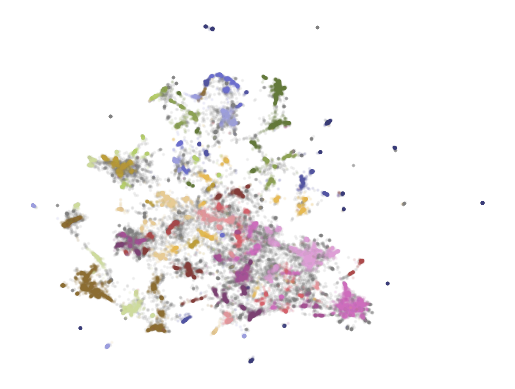

In [19]:
import matplotlib.pyplot as plt

# Plot outliers and non-outliers separately
plt.scatter(outliers.x, outliers.y, alpha = 0.08, s=2, c="grey")

plt.scatter(to_plot.x,
            to_plot.y,
            c = to_plot.cluster.astype(int),
            alpha=0.1,
            s = 2,
            cmap = 'tab20b',
            )
plt.axis('off')

In [2]:
pip install bertopic

In [3]:
from bertopic import BERTopic

# Train our model with our previously defined models

topic_model = BERTopic(
    embedding_model = embedding_model,
    umap_model = umap_model,
    hdbscan_model = hdbscan_model,
    verbose = True,
).fit(abstracts, embeddings)


topic_model.get_topic_info()

NameError: name 'embedding_model' is not defined